In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
units = pd.read_csv('units_L234.csv').copy()
print(units.columns)

Index(['pt_root_id', 'pt_position_x', 'pt_position_y', 'pt_position_z',
       'classification_system', 'brain_area', 'strategy_dendrite',
       'strategy_axon', 'layer', 'gOSI_data', 'pvals_ori_fdr', 'selective_ori',
       'pvals_dir_fdr', 'pref_ori_fit'],
      dtype='object')


In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

selected_mask (6448, 10)


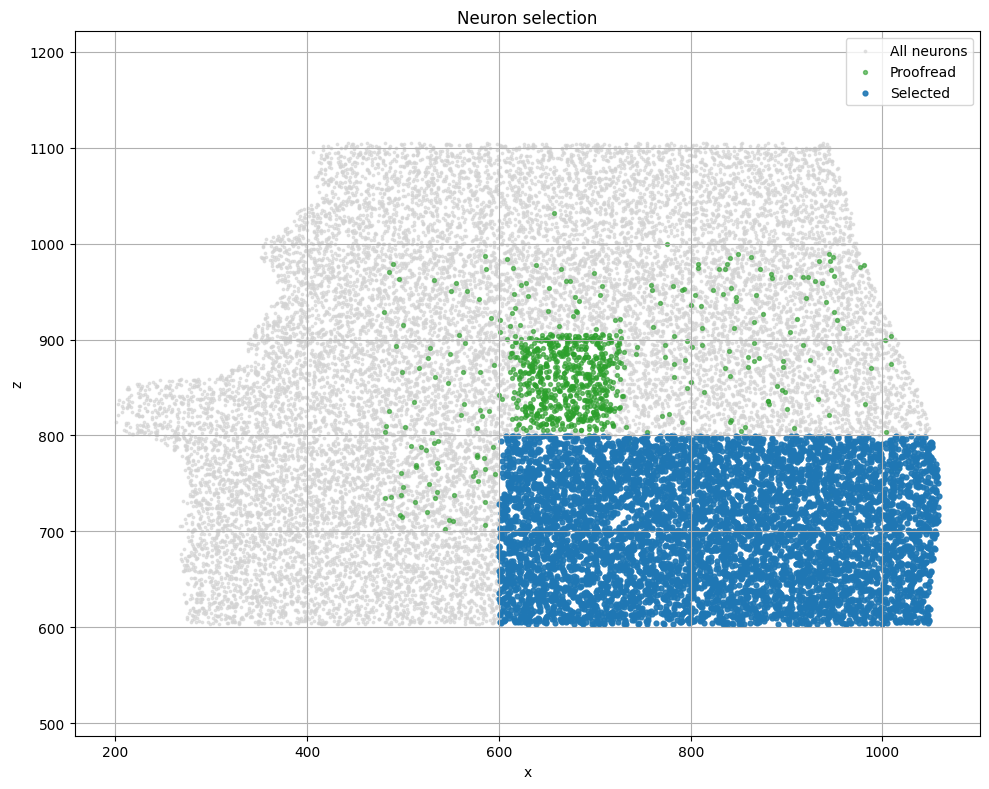

In [4]:
units_cleaned = clean_dataset(units)

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')]

selected_mask = units_cleaned[(units_cleaned["pt_position_z"] < 800) & (units_cleaned["pt_position_x"] > 600)]

print("selected_mask", selected_mask.shape)

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    selected_mask["pt_position_x"],
    selected_mask["pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [5]:
mask_exc = (selected_mask['classification_system'] == 'excitatory_neuron')
mask_inh = (selected_mask['classification_system'] == 'inhibitory_neuron')

mask_l23 = (selected_mask['layer'] == 'L2/3')
mask_l4 = (selected_mask['layer'] == 'L4')

In [6]:
E_L23 = selected_mask[mask_exc & mask_l23].copy().reset_index(drop=True)
print(E_L23.shape)
I_L23 = selected_mask[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = selected_mask[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = selected_mask[mask_inh & mask_l4].copy().reset_index(drop=True)

print(E_L23)

(3408, 10)
              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691136084469356     862.910950     166.053955     674.440002   
1     864691135156852068     895.572205     134.926117     688.919983   
2     864691135772608763     930.297302     153.639816     719.039978   
3     864691135489181498     929.746094     247.324280     750.239990   
4     864691135856593454     669.007080     172.089081     619.799988   
...                  ...            ...            ...            ...   
3403  864691135644599279     888.780762      86.983772     613.840027   
3404  864691135468547212     650.351379     123.172989     799.400024   
3405  864691136362442466     788.676208     101.803474     795.919983   
3406  864691135429292592    1028.933472     105.669991     641.440002   
3407  864691136238038799     708.155273     187.977524     799.599976   

     classification_system strategy_axon layer  gOSI_data selective_ori  \
0        excitatory_neuron          n

In [7]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [8]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [9]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [10]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [11]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z'
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [12]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    id_to_pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
    ]

    positions = id_to_pos.loc[
        np.array(all_ids)
    ].values.astype(np.float32)

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values

    positions = (positions - positions.mean(axis=0, keepdims=True)) / (positions.std(axis=0, keepdims=True)+ 1e-8)

    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = [
    "pre_pt_position_x",
    "pre_pt_position_y",
    "pre_pt_position_z",
    "post_pt_position_x",
    "post_pt_position_y",
    "post_pt_position_z",
    ]

    print(df)

    X = df[features].to_numpy(dtype=np.float32)
    y = df['label'].values

    return X, y, features, pre_idx, post_idx, positions

In [13]:
path, pre, post = pathways[0]
print(pre)
X, y, features, pre_idx, post_idx, positions = build_dataset(pre, post, synapses, metric=['Euclidean'])

              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691136084469356     862.910950     166.053955     674.440002   
1     864691135156852068     895.572205     134.926117     688.919983   
2     864691135772608763     930.297302     153.639816     719.039978   
3     864691135489181498     929.746094     247.324280     750.239990   
4     864691135856593454     669.007080     172.089081     619.799988   
...                  ...            ...            ...            ...   
3403  864691135644599279     888.780762      86.983772     613.840027   
3404  864691135468547212     650.351379     123.172989     799.400024   
3405  864691136362442466     788.676208     101.803474     795.919983   
3406  864691135429292592    1028.933472     105.669991     641.440002   
3407  864691136238038799     708.155273     187.977524     799.599976   

     classification_system strategy_axon layer  gOSI_data selective_ori  \
0        excitatory_neuron          none  L2/3  

In [14]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_hybrid_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 30
PATIENCE = 5
LR = 1e-3
DIMS = [1,2,3]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [15]:
# =========================
# Hybrid model: geometry + latent embedding
# =========================

class EmbeddingModel(nn.Module):
    def __init__(
        self,
        n_neurons,
        dim=2,
        hidden=64,
        positions=None,
    ):
        super().__init__()

        self.dim = dim

        # Latent part learned by backpropagation
        self.Z = nn.Embedding(
            n_neurons,
            dim
        )

        nn.init.normal_(
            self.Z.weight,
            mean=0.0,
            std=0.1
        )

        # Fixed anatomical positions
        if positions is None:
            raise ValueError(
                "positions must be provided with shape (n_neurons, 3)"
            )

        positions = torch.as_tensor(
            positions,
            dtype=torch.float32
        )

        if positions.shape != (n_neurons, 3):
            raise ValueError(
                f"positions must have shape ({n_neurons}, 3), "
                f"got {positions.shape}"
            )

        self.register_buffer(
            "positions",
            positions
        )

        # For each neuron:
        # [x, y, z] + latent dim
        neuron_feature_dim = 3 + dim

        # For each pair:
        # pre features + post features
        input_dim = 2 * neuron_feature_dim

        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, pre_idx, post_idx):
        # Learned latent vectors
        z_pre = self.Z(pre_idx)
        z_post = self.Z(post_idx)

        # Fixed anatomical positions
        pos_pre = self.positions[pre_idx]
        pos_post = self.positions[post_idx]

        # Hybrid neuron vectors
        h_pre = torch.cat(
            [pos_pre, z_pre],
            dim=1
        )

        h_post = torch.cat(
            [pos_post, z_post],
            dim=1
        )

        # Pair vector
        x = torch.cat(
            [h_pre, h_post],
            dim=1
        )

        logits = self.mlp(x).squeeze(1)

        return logits

    def forward(self, pre_idx, post_idx):
        return torch.sigmoid(
            self.forward_logits(pre_idx, post_idx)
        )

In [16]:
# =========================
# Data
# =========================

_, y, _, pre_idx, post_idx, positions = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

71408
11611056
              pre_pt_root_id     post_pt_root_id      size  pre_pt_position_x  \
0         864691134884804602  864691136267238900  1.048946         793.389404   
1         864691134885076730  864691135719709489  0.017885         890.064514   
2         864691134885076730  864691135841733859  0.071092         890.064514   
3         864691134885518074  864691136700131694  0.041582         699.402466   
4         864691134885576442  864691136811834227  1.107519         927.851685   
...                      ...                 ...       ...                ...   
11682459  864691136238038799  864691136663328222  0.000000         708.155273   
11682460  864691136238038799  864691135644599279  0.000000         708.155273   
11682461  864691136238038799  864691135468547212  0.000000         708.155273   
11682462  864691136238038799  864691136362442466  0.000000         708.155273   
11682463  864691136238038799  864691135429292592  0.000000         708.155273   

          pr

In [17]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb in loader:

            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [18]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [19]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [20]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [42]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(n_neurons=n_neurons, dim=dim, positions=positions).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
dim=01 | epoch=000 | train_loss=0.1759 | val_loss=0.0404 | val_auc=0.6717
dim=01 | epoch=001 | train_loss=0.0364 | val_loss=0.0351 | val_auc=0.7654
dim=01 | epoch=002 | train_loss=0.0341 | val_loss=0.0337 | val_auc=0.8261
dim=01 | epoch=003 | train_loss=0.0327 | val_loss=0.0323 | val_auc=0.8628
dim=01 | epoch=004 | train_loss=0.0314 | val_loss=0.0311 | val_auc=0.8832
dim=01 | epoch=005 | train_loss=0.0303 | val_loss=0.0301 | val_auc=0.8948
dim=01 | epoch=006 | train_loss=0.0294 | val_loss=0.0294 | val_auc=0.9016
dim=01 | epoch=007 | train_loss=0.0289 | val_loss=0.0290 | val_auc=0.9056
dim=01 | epoch=008 | train_loss=0.0285 | val_loss=0.0287 | val_auc=0.9080
dim=01 | epoch=009 | train_loss=0.0283 | val_loss=0.0286 | val_auc=0.9092
dim=01 | epoch=010 | train_loss=0.0282 | val_loss=0.0285 | val_auc=0.9099
dim=01 | epoch=011 | train_loss=0.0282 | val_loss=0.0285 | val_auc=0.9102
dim=01 | epoch=012 | train_loss=0.0281 | val_loss=0.0285 | val_auc=0.9105
dim=01 | epoch=013 |

KeyboardInterrupt: 

In [61]:
import pickle
import h5py
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================

FOUNDATION_PATH = "MICrONS\\readout_info\\foundation_model.pkl"
MICRONS_H5_PATH = "MICrONS\\microns.h5"
COREG_PATH = "coreg_v1300.csv"


# ============================================================
# Load files
# ============================================================

with open(FOUNDATION_PATH, "rb") as f:
    foundation = pickle.load(f)
    """{"session_scan": {
            mu: [mu_x, mu_x] #area of the vision field where focus on the neuron
            feature_weigth: [[128 features] * 4] visual caracteristic of this area learnt by a the model
        }
    }"""

h5 = h5py.File(MICRONS_H5_PATH, "r") #for more information see the folder on hugging face https://huggingface.co/datasets/NeuroBLab/MICrONS
print(h5)
coreg = pd.read_csv(COREG_PATH) #merging table with coreg["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]

print(coreg.columns)

print(h5)


# ============================================================
# Build readout table
# ============================================================

def build_readout_df(model_dict, h5, model_name="model"):
    rows = []
    for session_scan, data in model_dict.items():
        if session_scan not in h5["sessions"]:
            print("Missing in h5:", session_scan)
            continue

        session, scan_idx = map(int, session_scan.split("_"))
        meta = h5["sessions"][session_scan]["meta"]
        print(meta.keys())
        unit_ids = meta["unit_ids"][:]
        weights = data["feature_weights"]
        mu = data["mu"]

        n = min(len(unit_ids), weights.shape[0], mu.shape[0])

        if len(unit_ids) != weights.shape[0]:
            print(
                f"WARNING {model_name} {session_scan}: "
                f"unit_ids={len(unit_ids)}, weights={weights.shape[0]}, using n={n}"
            )

        for i in range(n):
            rows.append({
                "model_name": model_name,
                "session": session,
                "scan_idx": scan_idx,
                "unit_id": int(unit_ids[i]),
                "readout_weight": weights[i].reshape(-1).astype(np.float32),
                "readout_mu_x": float(mu[i, 0]),
                "readout_mu_y": float(mu[i, 1]),
            })
    return pd.DataFrame(rows)


readout_df = build_readout_df(foundation, h5)


# ============================================================
# Clean coreg table
# ============================================================

coreg = coreg[
    ["session", "scan_idx", "unit_id", "pt_root_id", "residual", "score"]
].copy()

coreg["session"] = coreg["session"].astype(int)
coreg["scan_idx"] = coreg["scan_idx"].astype(int)
coreg["unit_id"] = coreg["unit_id"].astype(int)
coreg["pt_root_id"] = coreg["pt_root_id"].astype(np.int64)
print(coreg["score"].describe())

print(coreg["residual"].describe())

# ============================================================
# Merge readouts with pt_root_id
# ============================================================

readout_with_root = readout_df.merge(
    coreg,
    on=["session", "scan_idx", "unit_id"],
    how="inner"
)

readout_with_root = readout_with_root[
    (readout_with_root["residual"] < 30)
    & (readout_with_root["score"] > 0)
].copy()

idx = (
    readout_with_root
    .groupby("pt_root_id")["score"]
    .idxmax()
)

readout_unique = (
    readout_with_root
    .loc[idx]
    .reset_index(drop=True)
)

print("readout_df:", readout_df.shape)
print("readout_with_root:", readout_with_root.shape)
print("readout_with_root:", readout_with_root.shape)
print("matched fraction:", len(readout_with_root) / len(readout_df))



<HDF5 file "microns.h5" (mode r)>
Index(['id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_supervoxel_id',
       'pt_root_id', 'id', 'created', 'valid', 'target_id', 'session',
       'scan_idx', 'unit_id', 'field', 'residual', 'score', 'pt_position',
       'bb_start_position', 'bb_end_position'],
      dtype='object')
<HDF5 file "microns.h5" (mode r)>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinates', 'unit_ids']>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinates', 'unit_ids']>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinates', 'unit_ids']>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinates', 'unit_ids']>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinates', 'unit_ids']>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinates', 'unit_ids']>
<KeysViewHDF5 ['area_indices', 'brain_areas', 'condition_hashes', 'coordinate

In [62]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    positions=positions
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

# ============================================================
# Remove duplicates
# ============================================================

units_unique = (
    units_cleaned
    .drop_duplicates(
        subset="pt_root_id",
        keep="first"
    )
    .copy()
)

print(
    "Duplicates in units_unique:",
    units_unique["pt_root_id"].duplicated().sum()
)


# ============================================================
# Build df_Z_full
# ============================================================

df_Z_full = df_Z.merge(
    units_unique,
    on="pt_root_id",
    how="left"
)
print(df_Z_full.head())

Loaded model for dim=1
Best epoch: 29
Best val loss: 0.0284
Z shape: (3408, 1)
Duplicates in units_unique: 0
         z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0  0.143915           0  864691134884804602     793.389404     242.525742   
1  0.501523           1  864691134885076730     890.064514     212.565536   
2  0.329397           2  864691134885518074     699.402466     200.638855   
3  0.114838           3  864691134885576442     927.851685     102.287254   
4 -0.071351           4  864691134885584634     754.282288     122.629097   

   pt_position_z classification_system strategy_axon layer  gOSI_data  \
0     721.359985     excitatory_neuron          none  L2/3   0.331749   
1     651.479980     excitatory_neuron          none  L2/3   0.031775   
2     603.599976     excitatory_neuron          none  L2/3   0.300022   
3     669.320007     excitatory_neuron          none  L2/3        NaN   
4     638.640015     excitatory_neuron          none  L2/3   0.

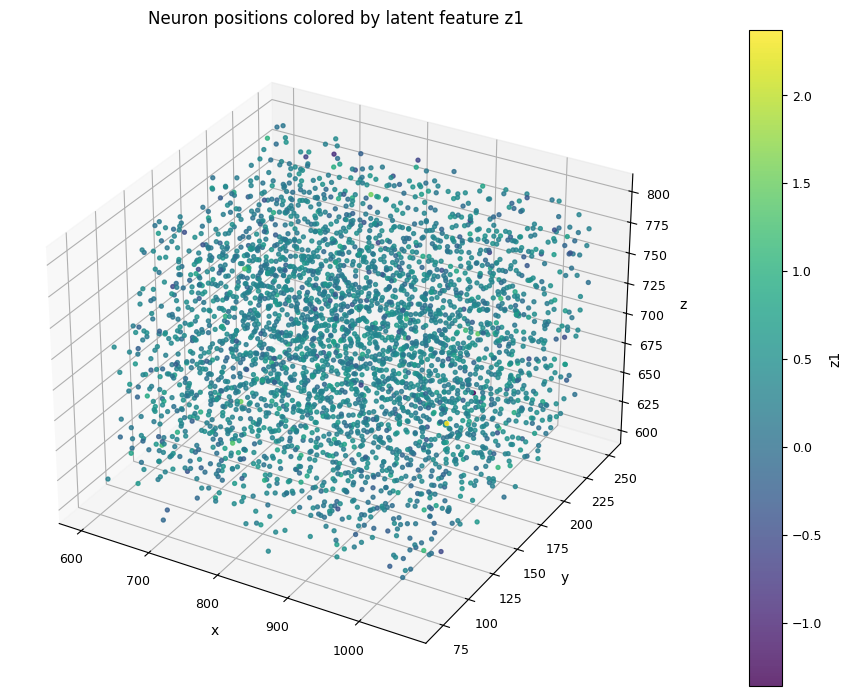

In [63]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


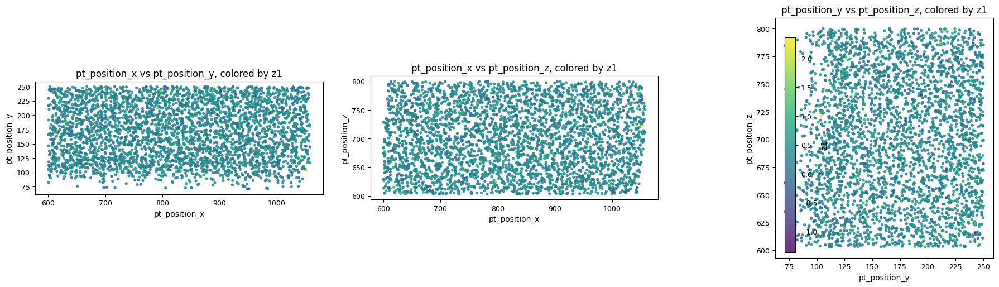

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

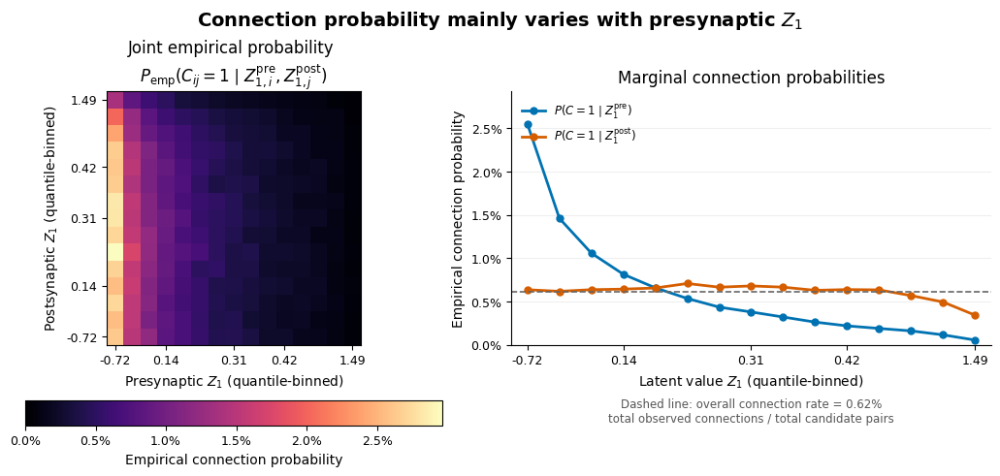

In [65]:
# ============================================================
# Empirical connection probability across Z1
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

K = 0
N_BINS = 15
MIN_PAIRS_PER_CELL = 5_000


# ------------------------------------------------------------
# Extract data
# ------------------------------------------------------------

pre_np = pre_idx.detach().cpu().numpy()
post_np = post_idx.detach().cpu().numpy()
y_np = y.detach().cpu().numpy().astype(float).reshape(-1)

z_pre = Z[pre_np, K]
z_post = Z[post_np, K]


# ------------------------------------------------------------
# Quantile-based bins
# ------------------------------------------------------------

active_neurons = np.unique(
    np.concatenate([pre_np, post_np])
)

z_neurons = Z[active_neurons, K]

z_edges = np.quantile(
    z_neurons,
    np.linspace(0, 1, N_BINS + 1),
)

z_edges = np.unique(z_edges)

if len(z_edges) < 3:
    raise ValueError(
        "Not enough distinct latent values to construct bins."
    )

z_centers = 0.5 * (
    z_edges[:-1] + z_edges[1:]
)


# ------------------------------------------------------------
# Empirical probabilities
# ------------------------------------------------------------

n_possible, _, _ = np.histogram2d(
    z_pre,
    z_post,
    bins=[z_edges, z_edges],
)

n_connections, _, _ = np.histogram2d(
    z_pre,
    z_post,
    bins=[z_edges, z_edges],
    weights=y_np,
)

probability = np.divide(
    n_connections,
    n_possible,
    out=np.full_like(
        n_connections,
        np.nan,
        dtype=float,
    ),
    where=n_possible > 0,
)

probability[
    n_possible < MIN_PAIRS_PER_CELL
] = np.nan


# ------------------------------------------------------------
# Marginal probabilities
# ------------------------------------------------------------

pre_denominator = n_possible.sum(axis=1)
post_denominator = n_possible.sum(axis=0)

pre_probability = np.divide(
    n_connections.sum(axis=1),
    pre_denominator,
    out=np.full_like(
        pre_denominator,
        np.nan,
        dtype=float,
    ),
    where=pre_denominator > 0,
)

post_probability = np.divide(
    n_connections.sum(axis=0),
    post_denominator,
    out=np.full_like(
        post_denominator,
        np.nan,
        dtype=float,
    ),
    where=post_denominator > 0,
)

global_probability = (
    n_connections.sum()
    / n_possible.sum()
)


# ------------------------------------------------------------
# Full color scale
# ------------------------------------------------------------

finite_values = probability[
    np.isfinite(probability)
]

if finite_values.size == 0:
    raise ValueError(
        "No cell satisfies the minimum-support criterion."
    )

# Use the true maximum: no clipping
vmax = np.nanmax(finite_values)


# ============================================================
# Clean two-panel figure
# ============================================================

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

n_actual_bins = probability.shape[0]
bin_numbers = np.arange(1, n_actual_bins + 1)


# ------------------------------------------------------------
# Tick positions with actual Z1 values
# ------------------------------------------------------------

tick_indices = np.linspace(
    0,
    n_actual_bins - 1,
    5,
    dtype=int,
)

tick_positions = tick_indices + 1

tick_labels = [
    f"{z_centers[index]:.2f}"
    for index in tick_indices
]


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(10.2, 4.8),
    layout="constrained",
)

grid = fig.add_gridspec(
    2,
    2,
    width_ratios=[1, 1.15],
    height_ratios=[1, 0.10],
)

ax_heatmap = fig.add_subplot(grid[0, 0])
ax_marginal = fig.add_subplot(grid[0, 1])

# Dedicated colorbar axis
ax_colorbar = fig.add_subplot(grid[1, 0])

# Dedicated explanation axis
ax_definition = fig.add_subplot(grid[1, 1])
ax_definition.axis("off")


cmap = mpl.colormaps["magma"].copy()
cmap.set_bad("#E6E6E6")


# ============================================================
# Left panel: heatmap
# ============================================================

image = ax_heatmap.imshow(
    probability.T,
    origin="lower",
    interpolation="nearest",
    aspect="equal",
    cmap=cmap,
    vmin=0,
    vmax=vmax,
    extent=[
        0.5,
        n_actual_bins + 0.5,
        0.5,
        n_actual_bins + 0.5,
    ],
)

ax_heatmap.set_xlabel(
    r"Presynaptic $Z_1$ (quantile-binned)"
)

ax_heatmap.set_ylabel(
    r"Postsynaptic $Z_1$ (quantile-binned)"
)

ax_heatmap.set_title(
    "Joint empirical probability \n"
    r"$P_{\mathrm{emp}}"
    r"(C_{ij}=1 \mid Z_{1,i}^{\mathrm{pre}},"
    r" Z_{1,j}^{\mathrm{post}})$"
)

# Actual latent values instead of Low / Median / High
ax_heatmap.set_xticks(
    tick_positions,
    labels=tick_labels,
)

ax_heatmap.set_yticks(
    tick_positions,
    labels=tick_labels,
)


# ------------------------------------------------------------
# Horizontal colorbar
# ------------------------------------------------------------

colorbar = fig.colorbar(
    image,
    cax=ax_colorbar,
    orientation="horizontal",
)

colorbar.set_label(
    "Empirical connection probability"
)

colorbar.ax.xaxis.set_major_formatter(
    PercentFormatter(
        xmax=1,
        decimals=1,
    )
)


# ============================================================
# Right panel: marginal probabilities
# ============================================================

ax_marginal.plot(
    bin_numbers,
    pre_probability,
    color="#0072B2",
    marker="o",
    markersize=5,
    linewidth=2,
    label=r"$P(C=1 \mid Z_{1}^{\mathrm{pre}})$",
)

ax_marginal.plot(
    bin_numbers,
    post_probability,
    color="#D55E00",
    marker="o",
    markersize=5,
    linewidth=2,
    label=r"$P(C=1 \mid Z_{1}^{\mathrm{post}})$",
)

# Overall connection rate
ax_marginal.axhline(
    global_probability,
    color="#666666",
    linestyle="--",
    linewidth=1.2,
)

ax_marginal.set_xlabel(
    r"Latent value $Z_1$ (quantile-binned)"
)

ax_marginal.set_ylabel(
    "Empirical connection probability"
)

ax_marginal.set_title(
    "Marginal connection probabilities"
)

# Actual Z1 values
ax_marginal.set_xticks(
    tick_positions,
    labels=tick_labels,
)

ax_marginal.set_xlim(
    0.5,
    n_actual_bins + 0.5,
)

maximum_probability = max(
    np.nanmax(pre_probability),
    np.nanmax(post_probability),
)

ax_marginal.set_ylim(
    0,
    maximum_probability * 1.15,
)

ax_marginal.yaxis.set_major_formatter(
    PercentFormatter(
        xmax=1,
        decimals=1,
    )
)

ax_marginal.grid(
    axis="y",
    alpha=0.2,
)

ax_marginal.spines[
    ["top", "right"]
].set_visible(False)

# Only the two marginal curves appear in the legend
ax_marginal.legend(
    frameon=False,
    fontsize=8.5,
    loc="upper left",
)


# ------------------------------------------------------------
# Definition of the dashed line
# ------------------------------------------------------------

ax_definition.text(
    0.5,
    0.55,
    (
        "Dashed line: overall connection rate "
        f"= {global_probability:.2%}\n"
        "total observed connections / total candidate pairs"
    ),
    ha="center",
    va="center",
    fontsize=8.5,
    color="#555555",
)


# ============================================================
# Global title and export
# ============================================================

fig.suptitle(
    r"Connection probability mainly varies with "
    r"presynaptic $Z_1$",
    fontsize=14,
    fontweight="semibold",
)

plt.savefig(
    "empirical_connection_probability_Z1_clean.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.savefig(
    "empirical_connection_probability_Z1_clean.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()

Neurons per group: [341 341 341 341 341 341 341 341 340 340]


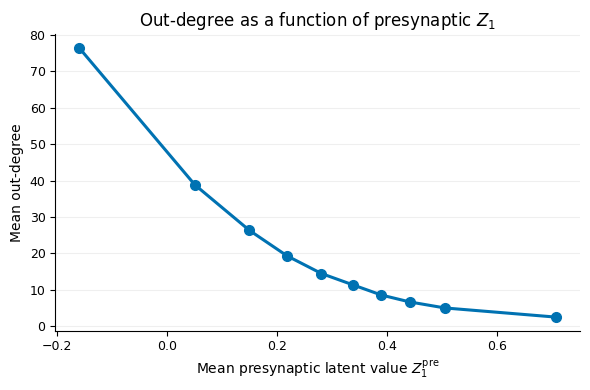

In [66]:
import numpy as np
import matplotlib.pyplot as plt

N_BINS = 10

# Pair-level arrays
pre_np = pre_idx.detach().cpu().numpy()
y_np = y.detach().cpu().numpy().astype(float).reshape(-1)

n_neurons = Z.shape[0]

# Out-degree of every presynaptic neuron
out_degree = np.bincount(
    pre_np,
    weights=y_np,
    minlength=n_neurons,
)

# Number of candidate pairs for every presynaptic neuron
n_possible = np.bincount(
    pre_np,
    minlength=n_neurons,
)

# One Z1_pre value per presynaptic neuron
z1_pre = Z[:, 0]

# Keep neurons that actually occur as presynaptic neurons
valid = (
    (n_possible > 0)
    & np.isfinite(z1_pre)
    & np.isfinite(out_degree)
)

z1_pre = z1_pre[valid]
out_degree = out_degree[valid]

# Sort neurons according to Z1_pre
sorted_indices = np.argsort(z1_pre)

# Groups with the same number of neurons
groups = np.array_split(
    sorted_indices,
    N_BINS,
)

# Mean Z1_pre and mean out-degree in every group
mean_z1_pre = np.array([
    z1_pre[group].mean()
    for group in groups
])

mean_out_degree = np.array([
    out_degree[group].mean()
    for group in groups
])

group_sizes = np.array([
    len(group)
    for group in groups
])

print("Neurons per group:", group_sizes)

# Plot
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(
    mean_z1_pre,
    mean_out_degree,
    marker="o",
    markersize=7,
    linewidth=2.2,
    color="#0072B2",
)

ax.set_xlabel(
    r"Mean presynaptic latent value $Z_1^{\mathrm{pre}}$"
)

ax.set_ylabel(
    "Mean out-degree"
)

ax.set_title(
    r"Out-degree as a function of presynaptic $Z_1$"
)

ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

plt.savefig(
    "mean_out_degree_vs_Z1_pre.pdf",
    bbox_inches="tight",
)

plt.savefig(
    "mean_out_degree_vs_Z1_pre.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

Complete dataset: 11,611,056 pairs
Number of neurons: 3,408
Neurons retained: 3,408

Z1 and complete out-degree
Pearson: r = -0.7238, p = 0.000e+00
Spearman: rho = -0.9062, p = 0.000e+00

Z1 and complete in-degree
Pearson: r = -0.1612, p = 2.799e-21
Spearman: rho = -0.1503, p = 1.132e-18

Neurons per group: [341 341 341 341 341 341 341 341 340 340]


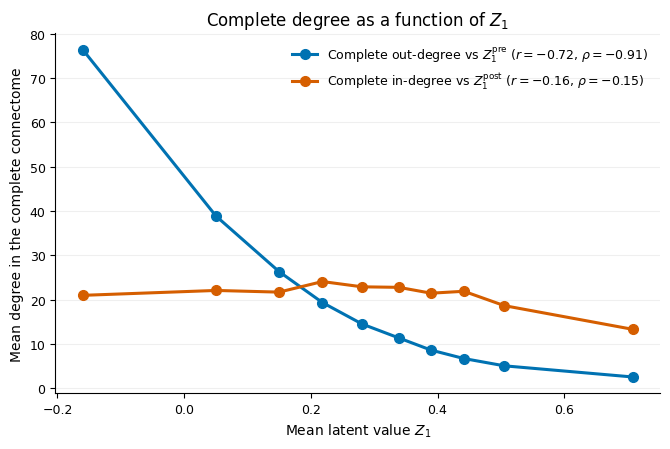

In [67]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr


N_BINS = 10


# ============================================================
# Complete pair-level arrays
# ============================================================

pre_np = (
    pre_idx.detach()
    .cpu()
    .numpy()
)

post_np = (
    post_idx.detach()
    .cpu()
    .numpy()
)

y_np = (
    y.detach()
    .cpu()
    .numpy()
    .astype(float)
    .reshape(-1)
)


# df_Z was created immediately after loading best_dim_1.pt.
# Using it prevents Z from being overwritten by later analyses.
z1 = df_Z["z1"].to_numpy(
    dtype=float
)

n_neurons = len(z1)

print(
    f"Complete dataset: {len(y_np):,} pairs"
)

print(
    f"Number of neurons: {n_neurons:,}"
)


# ============================================================
# Complete in-degree and out-degree
# ============================================================

out_degree = np.bincount(
    pre_np,
    weights=y_np,
    minlength=n_neurons,
)

in_degree = np.bincount(
    post_np,
    weights=y_np,
    minlength=n_neurons,
)


# Number of candidate pairs involving each neuron
n_possible_out = np.bincount(
    pre_np,
    minlength=n_neurons,
)

n_possible_in = np.bincount(
    post_np,
    minlength=n_neurons,
)


# Keep neurons occurring in both roles
valid = (
    (n_possible_out > 0)
    & (n_possible_in > 0)
    & np.isfinite(z1)
    & np.isfinite(out_degree)
    & np.isfinite(in_degree)
)

z1_valid = z1[valid]
out_degree_valid = out_degree[valid]
in_degree_valid = in_degree[valid]

print(
    f"Neurons retained: {valid.sum():,}"
)


# ============================================================
# Correlations on individual neurons
# ============================================================

out_pearson_r, out_pearson_p = pearsonr(
    z1_valid,
    out_degree_valid,
)

out_spearman_rho, out_spearman_p = spearmanr(
    z1_valid,
    out_degree_valid,
)

in_pearson_r, in_pearson_p = pearsonr(
    z1_valid,
    in_degree_valid,
)

in_spearman_rho, in_spearman_p = spearmanr(
    z1_valid,
    in_degree_valid,
)


print("\nZ1 and complete out-degree")

print(
    f"Pearson: r = {out_pearson_r:.4f}, "
    f"p = {out_pearson_p:.3e}"
)

print(
    f"Spearman: rho = {out_spearman_rho:.4f}, "
    f"p = {out_spearman_p:.3e}"
)


print("\nZ1 and complete in-degree")

print(
    f"Pearson: r = {in_pearson_r:.4f}, "
    f"p = {in_pearson_p:.3e}"
)

print(
    f"Spearman: rho = {in_spearman_rho:.4f}, "
    f"p = {in_spearman_p:.3e}"
)


# ============================================================
# Equal-sized groups ordered by Z1
# ============================================================

sorted_indices = np.argsort(
    z1_valid
)

groups = np.array_split(
    sorted_indices,
    N_BINS,
)


mean_z1 = np.array([
    z1_valid[group].mean()
    for group in groups
])

mean_out_degree = np.array([
    out_degree_valid[group].mean()
    for group in groups
])

mean_in_degree = np.array([
    in_degree_valid[group].mean()
    for group in groups
])

group_sizes = np.array([
    len(group)
    for group in groups
])

print(
    "\nNeurons per group:",
    group_sizes,
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.8, 4.6),
)


ax.plot(
    mean_z1,
    mean_out_degree,
    marker="o",
    markersize=7,
    linewidth=2.2,
    color="#0072B2",
    label=(
        rf"Complete out-degree vs "
        rf"$Z_1^{{\mathrm{{pre}}}}$ "
        rf"($r={out_pearson_r:.2f}$, "
        rf"$\rho={out_spearman_rho:.2f}$)"
    ),
)


ax.plot(
    mean_z1,
    mean_in_degree,
    marker="o",
    markersize=7,
    linewidth=2.2,
    color="#D55E00",
    label=(
        rf"Complete in-degree vs "
        rf"$Z_1^{{\mathrm{{post}}}}$ "
        rf"($r={in_pearson_r:.2f}$, "
        rf"$\rho={in_spearman_rho:.2f}$)"
    ),
)


ax.set_xlabel(
    r"Mean latent value $Z_1$"
)

ax.set_ylabel(
    "Mean degree in the complete connectome"
)

ax.set_title(
    r"Complete degree as a function of $Z_1$"
)


ax.grid(
    axis="y",
    alpha=0.2,
)

ax.spines[
    ["top", "right"]
].set_visible(False)


ax.legend(
    frameon=False,
    fontsize=9,
)


plt.tight_layout()


# ============================================================
# Export
# ============================================================

plt.savefig(
    "mean_complete_in_out_degree_vs_Z1.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.savefig(
    "mean_complete_in_out_degree_vs_Z1.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

Complete dataset: 11,611,056 pairs
Training set: 9,288,844 pairs
Training fraction: 80.0%
Neurons retained: 3,408

Z1 and training out-degree
Pearson: r = -0.7302, p = 0.000e+00
Spearman: rho = -0.9195, p = 0.000e+00

Z1 and training in-degree
Pearson: r = -0.1669, p = 1.052e-22
Spearman: rho = -0.1541, p = 1.472e-19

Neurons per group: [341 341 341 341 341 341 341 341 340 340]


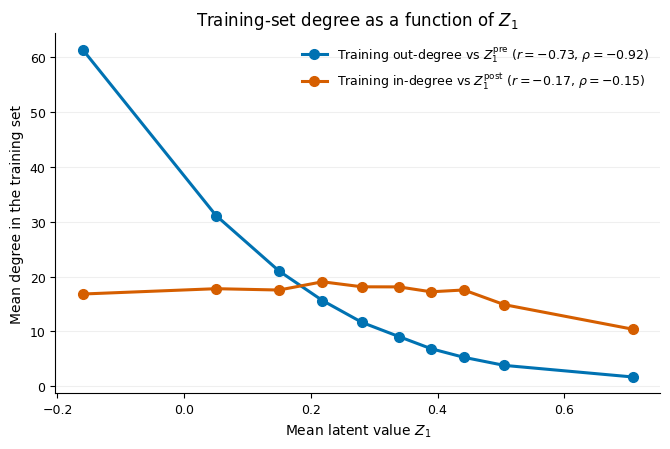

In [68]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr


N_BINS = 10


# ============================================================
# Complete pair-level arrays
# ============================================================

pre_np = (
    pre_idx.detach()
    .cpu()
    .numpy()
)

post_np = (
    post_idx.detach()
    .cpu()
    .numpy()
)

y_np = (
    y.detach()
    .cpu()
    .numpy()
    .astype(float)
    .reshape(-1)
)

n_neurons = Z.shape[0]


# ============================================================
# Recover the exact training pairs used by random_split
# ============================================================

train_pair_indices = np.asarray(
    train_set.indices,
    dtype=np.int64,
)

pre_train = pre_np[train_pair_indices]
post_train = post_np[train_pair_indices]
y_train = y_np[train_pair_indices]

print(f"Complete dataset: {len(y_np):,} pairs")
print(f"Training set: {len(y_train):,} pairs")
print(
    "Training fraction:",
    f"{len(y_train) / len(y_np):.1%}",
)


# ============================================================
# Partial degrees based only on the training set
# ============================================================

out_degree = np.bincount(
    pre_train,
    weights=y_train,
    minlength=n_neurons,
)

in_degree = np.bincount(
    post_train,
    weights=y_train,
    minlength=n_neurons,
)


# ============================================================
# Complete neuron population
# ============================================================

# These counts are computed on the complete dataset only to
# retain exactly the same neurons as in the previous figure.
# They are not used to calculate the degrees.
n_possible_out_complete = np.bincount(
    pre_np,
    minlength=n_neurons,
)

n_possible_in_complete = np.bincount(
    post_np,
    minlength=n_neurons,
)


# One Z1 value per neuron
z1 = Z[:, 0]


# Keep all neurons occurring in both roles in the complete
# connectome, including neurons with a training degree of zero.
valid = (
    (n_possible_out_complete > 0)
    & (n_possible_in_complete > 0)
    & np.isfinite(z1)
    & np.isfinite(out_degree)
    & np.isfinite(in_degree)
)

z1_valid = z1[valid]
out_degree_valid = out_degree[valid]
in_degree_valid = in_degree[valid]

print(
    f"Neurons retained: {valid.sum():,}"
)


# ============================================================
# Correlations on individual neurons
# ============================================================

out_pearson_r, out_pearson_p = pearsonr(
    z1_valid,
    out_degree_valid,
)

out_spearman_rho, out_spearman_p = spearmanr(
    z1_valid,
    out_degree_valid,
)

in_pearson_r, in_pearson_p = pearsonr(
    z1_valid,
    in_degree_valid,
)

in_spearman_rho, in_spearman_p = spearmanr(
    z1_valid,
    in_degree_valid,
)


print("\nZ1 and training out-degree")

print(
    f"Pearson: r = {out_pearson_r:.4f}, "
    f"p = {out_pearson_p:.3e}"
)

print(
    f"Spearman: rho = {out_spearman_rho:.4f}, "
    f"p = {out_spearman_p:.3e}"
)


print("\nZ1 and training in-degree")

print(
    f"Pearson: r = {in_pearson_r:.4f}, "
    f"p = {in_pearson_p:.3e}"
)

print(
    f"Spearman: rho = {in_spearman_rho:.4f}, "
    f"p = {in_spearman_p:.3e}"
)


# ============================================================
# Equal-sized neuron groups ordered by Z1
# ============================================================

sorted_indices = np.argsort(
    z1_valid
)

groups = np.array_split(
    sorted_indices,
    N_BINS,
)


mean_z1 = np.array([
    z1_valid[group].mean()
    for group in groups
])

mean_out_degree = np.array([
    out_degree_valid[group].mean()
    for group in groups
])

mean_in_degree = np.array([
    in_degree_valid[group].mean()
    for group in groups
])

group_sizes = np.array([
    len(group)
    for group in groups
])

print(
    "\nNeurons per group:",
    group_sizes,
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.8, 4.6),
)


ax.plot(
    mean_z1,
    mean_out_degree,
    marker="o",
    markersize=7,
    linewidth=2.2,
    color="#0072B2",
    label=(
        rf"Training out-degree vs "
        rf"$Z_1^{{\mathrm{{pre}}}}$ "
        rf"($r={out_pearson_r:.2f}$, "
        rf"$\rho={out_spearman_rho:.2f}$)"
    ),
)


ax.plot(
    mean_z1,
    mean_in_degree,
    marker="o",
    markersize=7,
    linewidth=2.2,
    color="#D55E00",
    label=(
        rf"Training in-degree vs "
        rf"$Z_1^{{\mathrm{{post}}}}$ "
        rf"($r={in_pearson_r:.2f}$, "
        rf"$\rho={in_spearman_rho:.2f}$)"
    ),
)


ax.set_xlabel(
    r"Mean latent value $Z_1$"
)

ax.set_ylabel(
    "Mean degree in the training set"
)

ax.set_title(
    r"Training-set degree as a function of $Z_1$"
)


ax.grid(
    axis="y",
    alpha=0.2,
)

ax.spines[
    ["top", "right"]
].set_visible(False)


ax.legend(
    frameon=False,
    fontsize=9,
)


plt.tight_layout()


# ============================================================
# Export
# ============================================================

plt.savefig(
    "mean_training_in_out_degree_vs_Z1.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.savefig(
    "mean_training_in_out_degree_vs_Z1.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

Loaded hybrid model with dimension 1 from epoch 29.

AUC summary


,Evaluation,AUC,Median neuron AUC,95% CI lower,95% CI upper,Eligible neurons
0,Global test AUC,0.9092,NaN,NaN,NaN,NaN
1,Fixed presynaptic neuron,0.8694,0.8962,0.8644,0.8739,2241.0
2,Fixed postsynaptic neuron,0.9039,0.9280,0.9005,0.9075,2711.0



Difference between fixed-presynaptic and global AUC: -0.0398
Difference between fixed-postsynaptic and global AUC: -0.0053


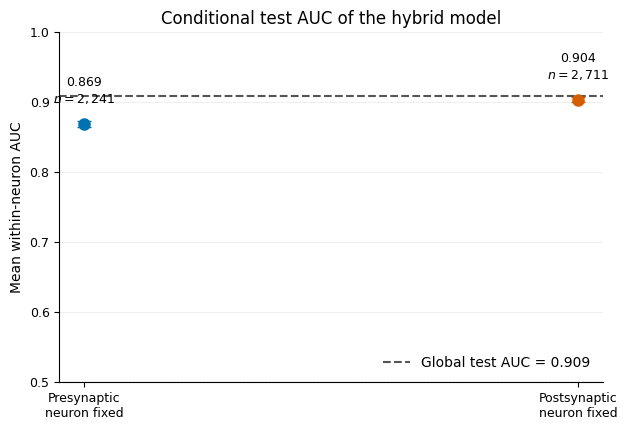

In [70]:
# ============================================================
# Global, fixed-presynaptic and fixed-postsynaptic AUC
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score


# ============================================================
# Load the best one-dimensional hybrid model
# ============================================================

DIM_AUC = 1

DIM_TO_ANALYZE = 1

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model_auc = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    positions=positions
).to(DEVICE)

auc_checkpoint = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False,
)

model_auc.load_state_dict(
    auc_checkpoint["model_state_dict"]
)

model_auc.eval()

print(
    f"Loaded hybrid model with dimension {DIM_AUC} "
    f"from epoch {auc_checkpoint['best_epoch']}."
)


# ============================================================
# Predictions on the test set
# ============================================================

test_pre = []
test_post = []
test_labels = []
test_predictions = []

with torch.no_grad():

    for pre_batch, post_batch, y_batch in test_loader:

        pre_batch = pre_batch.to(DEVICE)
        post_batch = post_batch.to(DEVICE)

        probability_batch = model_auc(
            pre_batch,
            post_batch,
        )

        test_pre.append(
            pre_batch.detach().cpu().numpy()
        )

        test_post.append(
            post_batch.detach().cpu().numpy()
        )

        test_labels.append(
            y_batch.detach().cpu().numpy()
        )

        test_predictions.append(
            probability_batch.detach().cpu().numpy()
        )


test_pre = np.concatenate(test_pre)
test_post = np.concatenate(test_post)

test_labels = (
    np.concatenate(test_labels)
    .astype(int)
    .reshape(-1)
)

test_predictions = (
    np.concatenate(test_predictions)
    .astype(float)
    .reshape(-1)
)


# ============================================================
# Global test AUC
# ============================================================

global_auc = roc_auc_score(
    test_labels,
    test_predictions,
)


# ============================================================
# AUC calculated separately for each neuron
# ============================================================

def calculate_auc_by_neuron(
    neuron_indices,
    labels,
    predictions,
    neuron_role,
):
    """
    Calculate one AUC for each neuron.

    A neuron is retained only if its test pairs contain
    at least one positive and one negative connection.
    """

    dataframe = pd.DataFrame({
        "neuron_index": neuron_indices,
        "label": labels,
        "prediction": predictions,
    })

    results = []

    for neuron_index, group in dataframe.groupby(
        "neuron_index",
        sort=False,
    ):

        group_labels = group["label"].to_numpy()

        n_positive = int(group_labels.sum())
        n_negative = int(
            len(group_labels) - n_positive
        )

        # The AUC is undefined if only one class is present
        if n_positive == 0 or n_negative == 0:
            continue

        neuron_auc = roc_auc_score(
            group_labels,
            group["prediction"].to_numpy(),
        )

        results.append({
            "neuron_index": int(neuron_index),
            "neuron_role": neuron_role,
            "n_pairs": len(group),
            "n_positive": n_positive,
            "n_negative": n_negative,
            "auc": neuron_auc,
        })

    return pd.DataFrame(results)


# AUC among the candidate partners of each presynaptic neuron
pre_auc_results = calculate_auc_by_neuron(
    neuron_indices=test_pre,
    labels=test_labels,
    predictions=test_predictions,
    neuron_role="presynaptic",
)

# AUC among the candidate sources of each postsynaptic neuron
post_auc_results = calculate_auc_by_neuron(
    neuron_indices=test_post,
    labels=test_labels,
    predictions=test_predictions,
    neuron_role="postsynaptic",
)


# ============================================================
# Summary statistics
# ============================================================

mean_pre_auc = pre_auc_results["auc"].mean()
median_pre_auc = pre_auc_results["auc"].median()

mean_post_auc = post_auc_results["auc"].mean()
median_post_auc = post_auc_results["auc"].median()


def bootstrap_mean_ci(
    values,
    n_bootstrap=2_000,
    confidence_level=0.95,
    seed=SEED,
):
    """Bootstrap confidence interval for the mean neuron AUC."""

    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)

    bootstrap_means = np.empty(
        n_bootstrap,
        dtype=float,
    )

    for bootstrap_index in range(n_bootstrap):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True,
        )

        bootstrap_means[bootstrap_index] = (
            sample.mean()
        )

    alpha = 1.0 - confidence_level

    return np.quantile(
        bootstrap_means,
        [
            alpha / 2,
            1.0 - alpha / 2,
        ],
    )


pre_ci_low, pre_ci_high = bootstrap_mean_ci(
    pre_auc_results["auc"]
)

post_ci_low, post_ci_high = bootstrap_mean_ci(
    post_auc_results["auc"]
)


summary_auc = pd.DataFrame({
    "Evaluation": [
        "Global test AUC",
        "Fixed presynaptic neuron",
        "Fixed postsynaptic neuron",
    ],
    "AUC": [
        global_auc,
        mean_pre_auc,
        mean_post_auc,
    ],
    "Median neuron AUC": [
        np.nan,
        median_pre_auc,
        median_post_auc,
    ],
    "95% CI lower": [
        np.nan,
        pre_ci_low,
        post_ci_low,
    ],
    "95% CI upper": [
        np.nan,
        pre_ci_high,
        post_ci_high,
    ],
    "Eligible neurons": [
        np.nan,
        len(pre_auc_results),
        len(post_auc_results),
    ],
})

print("\nAUC summary")
display(
    summary_auc.round(4)
)

print(
    "\nDifference between fixed-presynaptic "
    f"and global AUC: {mean_pre_auc - global_auc:+.4f}"
)

print(
    "Difference between fixed-postsynaptic "
    f"and global AUC: {mean_post_auc - global_auc:+.4f}"
)


# ============================================================
# Plot
# ============================================================

conditional_means = np.array([
    mean_pre_auc,
    mean_post_auc,
])

conditional_ci_lower = np.array([
    pre_ci_low,
    post_ci_low,
])

conditional_ci_upper = np.array([
    pre_ci_high,
    post_ci_high,
])

conditional_errors = np.vstack([
    conditional_means - conditional_ci_lower,
    conditional_ci_upper - conditional_means,
])

x_positions = np.arange(2)

fig, ax = plt.subplots(
    figsize=(6.4, 4.4),
)

colors = [
    "#0072B2",
    "#D55E00",
]

for x, mean_auc, errors, color in zip(
    x_positions,
    conditional_means,
    conditional_errors.T,
    colors,
):

    ax.errorbar(
        x,
        mean_auc,
        yerr=errors.reshape(2, 1),
        fmt="o",
        markersize=8,
        linewidth=2,
        capsize=5,
        color=color,
    )

ax.axhline(
    global_auc,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label=rf"Global test AUC = {global_auc:.3f}",
)

ax.axhline(
    0.5,
    color="#AAAAAA",
    linestyle=":",
    linewidth=1,
)

ax.set_xticks(
    x_positions,
    labels=[
        "Presynaptic\nneuron fixed",
        "Postsynaptic\nneuron fixed",
    ],
)

ax.set_ylabel(
    "Mean within-neuron AUC"
)

ax.set_title(
    r"Conditional test AUC of the hybrid model"
)

ax.set_ylim(
    0.5,
    1.0,
)

ax.grid(
    axis="y",
    alpha=0.2,
)

ax.spines[
    ["top", "right"]
].set_visible(False)

ax.legend(
    frameon=False,
    loc="lower right",
)

for x, value, n_neurons_valid in zip(
    x_positions,
    conditional_means,
    [
        len(pre_auc_results),
        len(post_auc_results),
    ],
):

    ax.annotate(
        f"{value:.3f}\n$n={n_neurons_valid:,}$",
        xy=(x, value),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()

plt.savefig(
    "conditional_auc_fixed_pre_post.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.savefig(
    "conditional_auc_fixed_pre_post.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


# ============================================================
# Save detailed results
# ============================================================

pre_auc_results.to_csv(
    "auc_by_presynaptic_neuron.csv",
    index=False,
)

post_auc_results.to_csv(
    "auc_by_postsynaptic_neuron.csv",
    index=False,
)

summary_auc.to_csv(
    "conditional_auc_summary.csv",
    index=False,
)

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\776809946.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = df.groupby("distance_bin").agg(


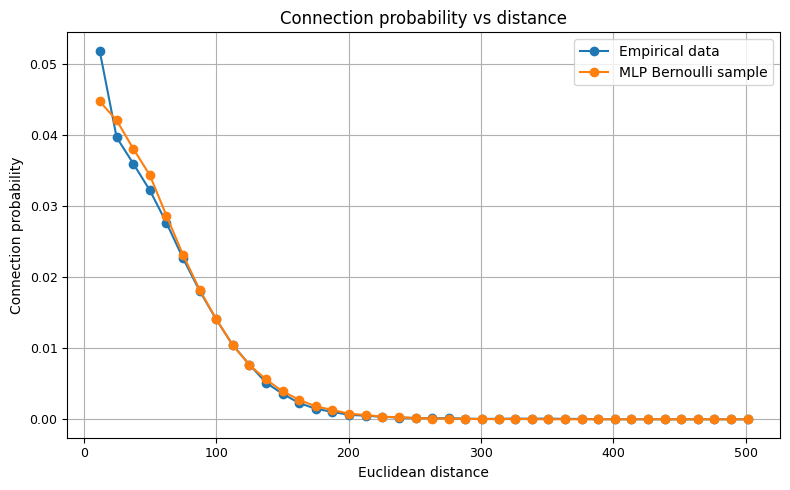

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Euclidean distances
# =========================

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

# =========================
# 3. MLP probabilities
# =========================

model.eval()

with torch.no_grad():
    p_mlp = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

# =========================
# 4. Bernoulli realization
# =========================

rng = np.random.default_rng(42)

y_mlp = rng.binomial(
    n=1,
    p=p_mlp
)

y_emp = y.cpu().numpy()

# =========================
# 5. Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "empirical": y_emp,
    "mlp": y_mlp
})

df["distance_bin"] = pd.cut(
    df["distance"],
    bins=40
)

# =========================
# 6. Compute connection probability per bin
# =========================

curve = df.groupby("distance_bin").agg(
    empirical_prob=("empirical", "mean"),
    mlp_prob=("mlp", "mean"),
    n_pairs=("empirical", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# =========================
# 7. Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical data"
)

plt.plot(
    centers,
    curve["mlp_prob"],
    marker="o",
    label="MLP Bernoulli sample"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 29
Best val loss: 0.0284


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.031

Analyzing dim = 2
Loaded best epoch: 29
Best val loss: 0.0281


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


...

corr(geometrical distance, latent distance) = 0.058

Analyzing dim = 5
Loaded best epoch: 29
Best val loss: 0.0275


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.025

Analyzing dim = 6
Loaded best epoch: 29
Best val loss: 0.0276


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:182: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\2039236649.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.032


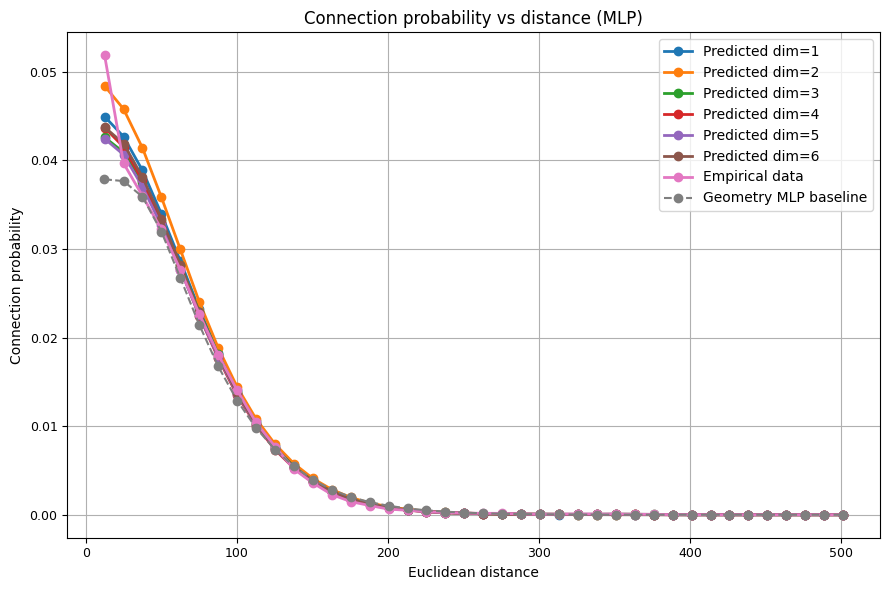

dim=6 corr=0.032


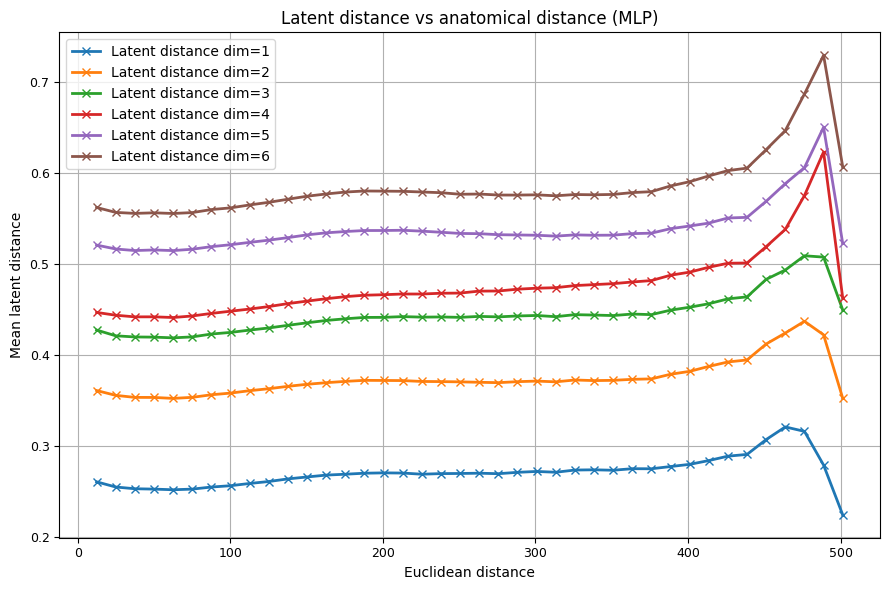

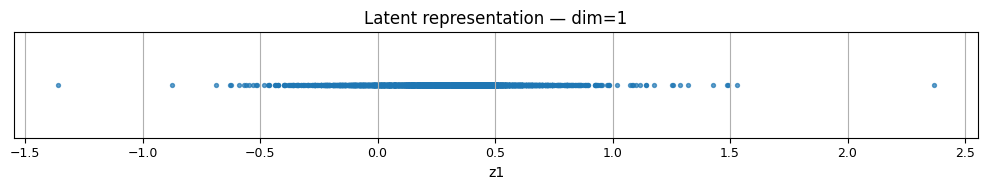

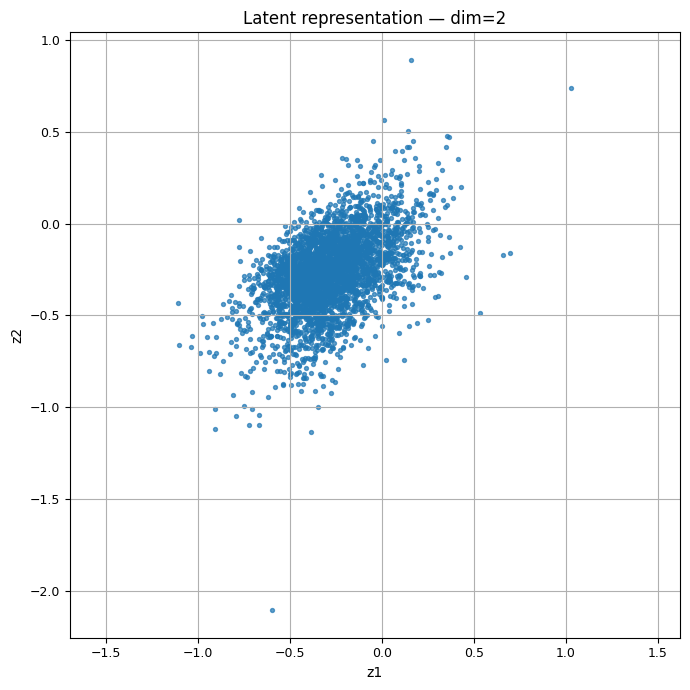

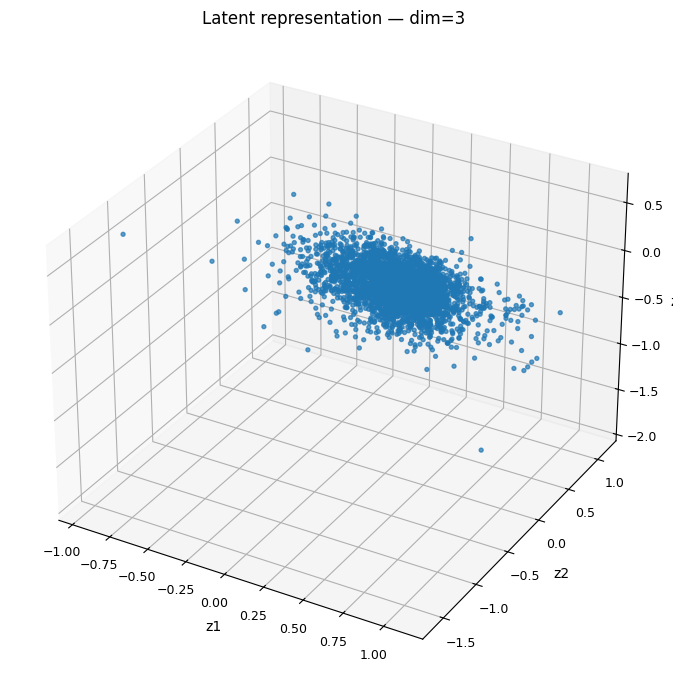

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 2, 3, 4, 5, 6]
N_BINS = 40
BATCH_SIZE = 32768


# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        positions=positions
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

baseline_curve = pd.read_csv(
        "baselines/geometry_mlp_probability_vs_distance.csv",
        index_col=0
    )

baseline_centers = np.array([
pd.Interval(left=float(s.split(",")[0][1:]),
            right=float(s.split(",")[1][:-1])).mid
for s in baseline_curve.index
])

plt.plot(
    baseline_curve["bin_center"],
    baseline_curve["predicted_prob"],
    marker="o",
    linestyle="--",
    label="Geometry MLP baseline"
)


plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="x",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (MLP)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np


# ============================================================
# Data
# ============================================================

df_Z_full = df_Z_full.merge(readout_unique[ 
    [ "pt_root_id", 
     "readout_weight", 
     "readout_mu_x", 
     "readout_mu_y", 
     "session", 
     "scan_idx", 
     "unit_id", 
     "residual", 
     "score" ] ], 
     on="pt_root_id", how="left" )

print(df_Z_full)


df_Z_readout = df_Z_full[
    df_Z_full["readout_weight"].notna()
].copy().reset_index(drop=True)
latent_cols = [c for c in df_Z_readout.columns if c.startswith("z")]

R = np.stack(df_Z_readout["readout_weight"].values)

print("R shape:", R.shape)

threshold = 0.30

results = []

# ============================================================
# Correlations
# ============================================================

for z in latent_cols:

    z_values = df_Z_readout[z].values

    for j in range(512):

        rho, pval = spearmanr(
            z_values,
            R[:, j]
        )

        if np.abs(rho) >= threshold:

            results.append({
                "latent": z,
                "readout_dim": j,
                "rho": rho,
                "abs_rho": abs(rho),
                "pvalue": pval,
            })

corr_df = pd.DataFrame(results)

"""corr_df = corr_df.sort_values(
    "abs_rho",
    ascending=False
)"""

print(corr_df)

            z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0     0.143915           0  864691134884804602     793.389404     242.525742   
1     0.501523           1  864691134885076730     890.064514     212.565536   
2     0.329397           2  864691134885518074     699.402466     200.638855   
3     0.114838           3  864691134885576442     927.851685     102.287254   
4    -0.071351           4  864691134885584634     754.282288     122.629097   
...        ...         ...                 ...            ...            ...   
3403  1.491354        3403  864691135657776514     630.523865     188.252563   
3404  1.017379        3404  864691136444759171     619.904053     224.456741   
3405  0.825607        3405  864691136091466676     617.484192     124.344887   
3406  0.974747        3406  864691136389610256     631.535583     220.013596   
3407  0.656916        3407  864691135583278189     782.394775     185.349930   

      pt_position_z classification_syst

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
    "readout_mu_x",
    "readout_mu_y"
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

Latent columns: ['z1']
Biological columns: ['pt_position_x', 'pt_position_y', 'pt_position_z', 'pref_ori_fit', 'readout_mu_x', 'readout_mu_y']


In [ ]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

=== Spearman correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1       0.020119       0.050248      -0.041732       0.03596      0.021923   

    readout_mu_y  
z1     -0.026111  

=== Pearson correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1       0.010766        0.03652      -0.050132      0.045212       0.01682   

    readout_mu_y  
z1     -0.029615  


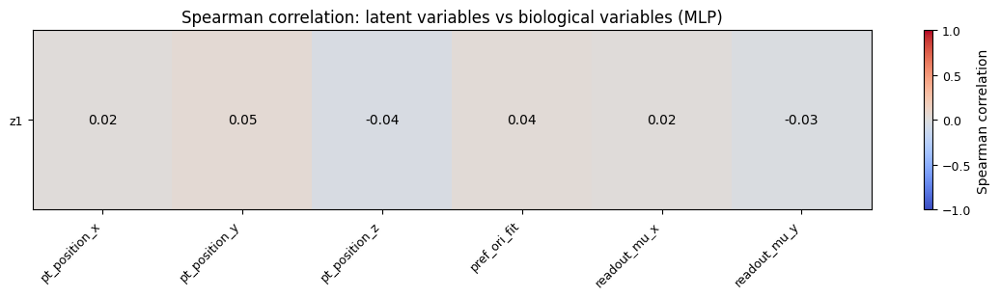

In [ ]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (MLP)")
plt.tight_layout()
plt.show()

=== Strongest correlations ===
z1  pt_position_y    0.050248
    pt_position_z    0.041732
    pref_ori_fit     0.035960
    readout_mu_y     0.026111
    readout_mu_x     0.021923
    pt_position_x    0.020119
dtype: float64


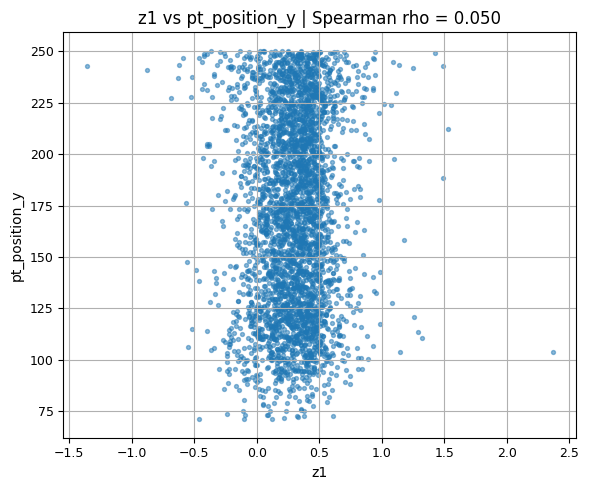

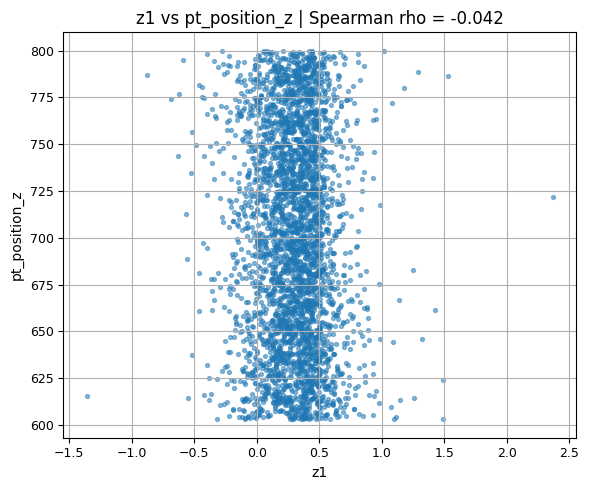

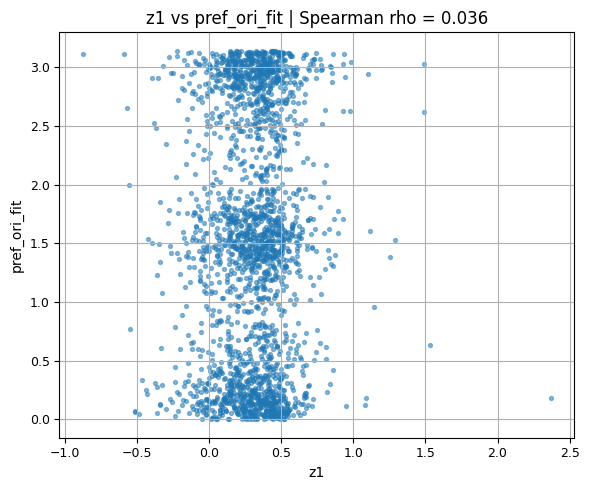

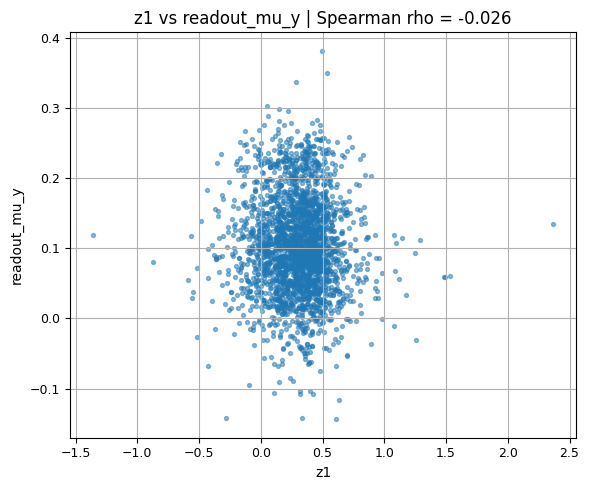

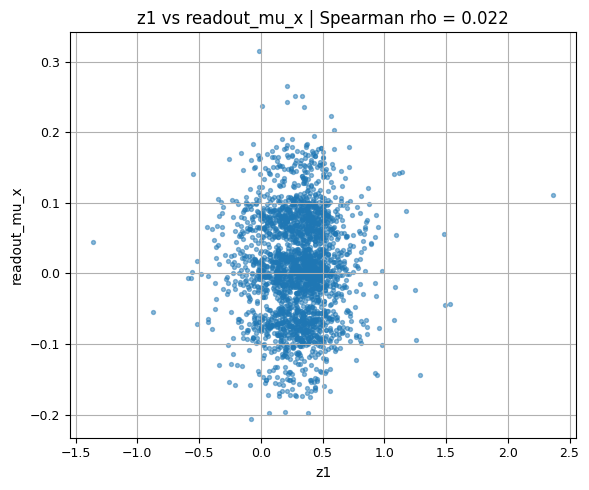

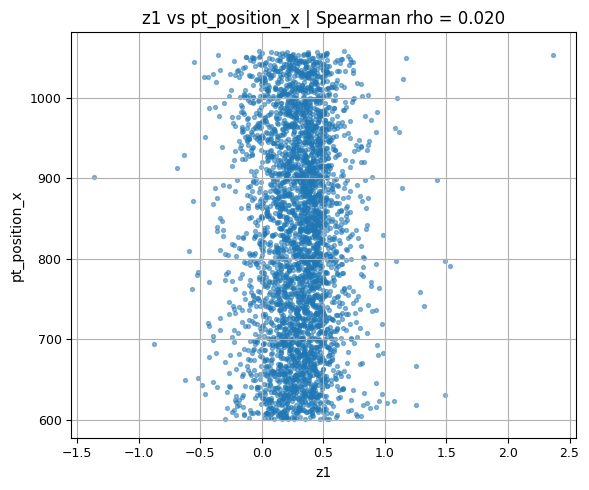

In [ ]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
            "readout_mu_x",
            "readout_mu_y"
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

PCA skipped: latent dimension < 2


In [ ]:
import pickle
import h5py
import pandas as pd

with open("MICrONS\\readout_info\\foundation_model.pkl", "rb") as f:
    foundation = pickle.load(f)

with open("MICrONS\\readout_info\\hierarchical_model.pkl", "rb") as f:
    hierarchical = pickle.load(f)

h5 = h5py.File("MICrONS\\microns.h5", "r")
print(h5.keys())

<KeysViewHDF5 ['brain_areas', 'sessions', 'types', 'videos']>


In [ ]:
def explore_h5(g, prefix=""):
    for k in g.keys():
        item = g[k]
        path = f"{prefix}/{k}"
        print(path, type(item), getattr(item, "shape", ""))
        if isinstance(item, h5py.Group):
            explore_h5(item, path)

explore_h5(h5)

/brain_areas <class 'h5py._hl.group.Group'> 
/brain_areas/AL <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7 <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices/AL <class 'h5py._hl.dataset.Dataset'> (387,)
/brain_areas/AL/4_7/meta/area_indices/LM <class 'h5py._hl.dataset.Dataset'> (983,)
/brain_areas/AL/4_7/meta/area_indices/RL <class 'h5py._hl.dataset.Dataset'> (811,)
/brain_areas/AL/4_7/meta/area_indices/V1 <class 'h5py._hl.dataset.Dataset'> (5312,)
/brain_areas/AL/4_7/meta/brain_areas <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/meta/condition_hashes <class 'h5py._hl.dataset.Dataset'> (464,)
/brain_areas/AL/4_7/meta/coordinates <class 'h5py._hl.dataset.Dataset'> (7493, 3)
/brain_areas/AL/4_7/meta/unit_ids <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/trials <class 'h5py._hl.group.Group'> 
/brain_areas/

Number of neurons: 2481
Readout shape: (2481, 512)
Latent shape: (2481, 1)

Best linear parameters:
{'regressor__ridge__alpha': np.float64(1000.0)}

Best MLP parameters:
{'regressor__mlp__alpha': 0.0001, 'regressor__mlp__hidden_layer_sizes': (32,)}

Whole-vector test metrics:


,test_R2,explained_variance,mean_euclidean,median_euclidean,pearson_r
model,,,,,
Linear,-0.0262,-0.0233,0.8140,0.6541,0.0768
Linear shuffled,-0.0678,-0.0635,0.8245,0.6763,-0.0017
MLP,-0.3355,-0.3266,0.9344,0.7138,-0.0210
MLP shuffled,-0.4379,-0.4263,0.9815,0.7760,-0.0791



Test R2 for each latent dimension:


,latent_dimension,Linear,Linear shuffled,MLP,MLP shuffled
0,z1,-0.0262,-0.0678,-0.3355,-0.4379



Note: cosine similarity is not informative for a one-dimensional latent space. Pearson correlation is reported instead.


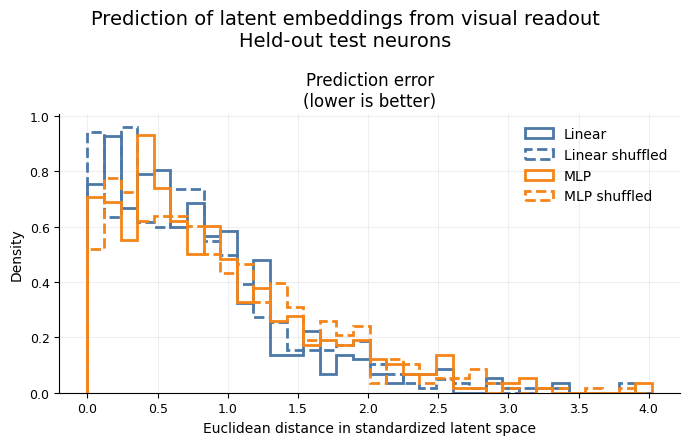

In [ ]:
# ============================================================
# How much of the latent vector Z is explained by visual readout?
#
# Models:
#   1. Linear Ridge regression
#   2. Nonlinear MLP
#   3. Ridge trained with shuffled readout/Z pairing
#   4. MLP trained with shuffled readout/Z pairing
#
# Evaluation:
#   - Hyperparameters selected by cross-validation on training neurons
#   - Final metrics calculated only on held-out test neurons
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    explained_variance_score,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# Parameters
# ============================================================

SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_JOBS = -1


# ============================================================
# Data
#
# R: visual readout vectors
# Z: complete latent embedding vectors
# ============================================================

latent_cols = sorted(
    [c for c in df_Z_readout.columns if c.startswith("z")],
    key=lambda c: int(c[1:]),
)

R = np.stack(
    df_Z_readout["readout_weight"].to_numpy()
).astype(np.float32)

Z_observed = df_Z_readout[
    latent_cols
].to_numpy(dtype=np.float32)


# Remove neurons containing invalid values
valid_rows = (
    np.isfinite(R).all(axis=1)
    & np.isfinite(Z_observed).all(axis=1)
)

R = R[valid_rows]
Z_observed = Z_observed[valid_rows]

n_neurons_analysis = len(R)
n_latent = Z_observed.shape[1]

print("Number of neurons:", n_neurons_analysis)
print("Readout shape:", R.shape)
print("Latent shape:", Z_observed.shape)


# ============================================================
# Train/test split by neuron
# ============================================================

all_indices = np.arange(n_neurons_analysis)

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=SEED,
)

R_train = R[train_indices]
R_test = R[test_indices]

Z_train = Z_observed[train_indices]
Z_test = Z_observed[test_indices]


# sklearn prefers a 1D target when there is only one output
def target_for_sklearn(Z):
    if Z.shape[1] == 1:
        return Z.ravel()
    return Z


def prediction_to_2d(prediction):
    prediction = np.asarray(prediction)

    if prediction.ndim == 1:
        prediction = prediction[:, None]

    return prediction


Z_train_fit = target_for_sklearn(Z_train)


# ============================================================
# Inner cross-validation
# ============================================================

inner_cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED,
)


# ============================================================
# 1. Linear model: Ridge regression
#
# X and Z are standardized inside each CV fold.
# ============================================================

linear_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "ridge",
            Ridge(),
        ),
    ]),
    transformer=StandardScaler(),
)

linear_search = GridSearchCV(
    estimator=linear_model,
    param_grid={
        "regressor__ridge__alpha": np.logspace(
            -3,
            3,
            7,
        )
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

linear_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_linear = prediction_to_2d(
    linear_search.predict(R_test)
)


# ============================================================
# 2. Nonlinear model: MLP
# ============================================================

mlp_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "mlp",
            MLPRegressor(
                activation="relu",
                solver="adam",
                batch_size=64,
                max_iter=1000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=20,
                random_state=SEED,
            ),
        ),
    ]),
    transformer=StandardScaler(),
)

mlp_search = GridSearchCV(
    estimator=mlp_model,
    param_grid={
        "regressor__mlp__hidden_layer_sizes": [
            (32,),
            (64,),
        ],
        "regressor__mlp__alpha": [
            1e-4,
            1e-3,
        ],
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

mlp_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_mlp = prediction_to_2d(
    mlp_search.predict(R_test)
)


# ============================================================
# Shuffled control
#
# Only the training correspondence between R and Z is shuffled.
# The test set remains unchanged.
#
# The shuffled models use the hyperparameters selected above,
# ensuring the same model complexity.
# ============================================================

rng = np.random.default_rng(SEED)

shuffle_order = rng.permutation(
    len(Z_train)
)

Z_train_shuffled = Z_train[
    shuffle_order
]

Z_train_shuffled_fit = target_for_sklearn(
    Z_train_shuffled
)


linear_shuffled_model = clone(
    linear_search.best_estimator_
)

linear_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_linear_shuffled = prediction_to_2d(
    linear_shuffled_model.predict(R_test)
)


mlp_shuffled_model = clone(
    mlp_search.best_estimator_
)

mlp_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_mlp_shuffled = prediction_to_2d(
    mlp_shuffled_model.predict(R_test)
)


# ============================================================
# Standardize the latent space using training statistics
#
# This prevents one latent dimension from dominating Euclidean
# distance simply because it has a larger numerical scale.
# ============================================================

Z_mean = Z_train.mean(
    axis=0,
    keepdims=True,
)

Z_std = Z_train.std(
    axis=0,
    keepdims=True,
)

Z_std = np.where(
    Z_std < 1e-8,
    1.0,
    Z_std,
)


def standardize_Z(Z):
    return (Z - Z_mean) / Z_std


Z_test_scaled = standardize_Z(
    Z_test
)

predictions_scaled = {
    "Linear": standardize_Z(
        Z_pred_linear
    ),
    "Linear shuffled": standardize_Z(
        Z_pred_linear_shuffled
    ),
    "MLP": standardize_Z(
        Z_pred_mlp
    ),
    "MLP shuffled": standardize_Z(
        Z_pred_mlp_shuffled
    ),
}


# ============================================================
# Vector metrics for each test neuron
# ============================================================

def cosine_by_neuron(Z_true, Z_pred):

    numerator = np.sum(
        Z_true * Z_pred,
        axis=1,
    )

    denominator = (
        np.linalg.norm(Z_true, axis=1)
        * np.linalg.norm(Z_pred, axis=1)
    )

    cosine = np.divide(
        numerator,
        denominator,
        out=np.full_like(
            numerator,
            np.nan,
            dtype=float,
        ),
        where=denominator > 1e-12,
    )

    return cosine


def euclidean_by_neuron(Z_true, Z_pred):

    return np.linalg.norm(
        Z_true - Z_pred,
        axis=1,
    )


vector_distributions = {}
metric_rows = []

for model_name, Z_prediction in predictions_scaled.items():

    euclidean_values = euclidean_by_neuron(
        Z_test_scaled,
        Z_prediction,
    )

    if n_latent >= 2:
        cosine_values = cosine_by_neuron(
            Z_test_scaled,
            Z_prediction,
        )
    else:
        # In one dimension, cosine is essentially only a sign test
        cosine_values = np.full(
            len(Z_test_scaled),
            np.nan,
        )

    vector_distributions[model_name] = {
        "cosine": cosine_values,
        "euclidean": euclidean_values,
    }

    row = {
        "model": model_name,

        "test_R2": r2_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "explained_variance": explained_variance_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "mean_euclidean": np.mean(
            euclidean_values
        ),

        "median_euclidean": np.median(
            euclidean_values
        ),
    }

    if n_latent >= 2:

        row["mean_cosine"] = np.nanmean(
            cosine_values
        )

        row["median_cosine"] = np.nanmedian(
            cosine_values
        )

    else:

        row["pearson_r"] = np.corrcoef(
            Z_test_scaled[:, 0],
            Z_prediction[:, 0],
        )[0, 1]

    metric_rows.append(row)


metrics_df = (
    pd.DataFrame(metric_rows)
    .set_index("model")
)


# ============================================================
# R2 for each individual latent dimension
# ============================================================

per_dimension_results = pd.DataFrame({
    model_name: r2_score(
        Z_test_scaled,
        Z_prediction,
        multioutput="raw_values",
    )
    for model_name, Z_prediction
    in predictions_scaled.items()
})

per_dimension_results.insert(
    0,
    "latent_dimension",
    latent_cols,
)


# ============================================================
# Results
# ============================================================

print("\nBest linear parameters:")
print(linear_search.best_params_)

print("\nBest MLP parameters:")
print(mlp_search.best_params_)

print("\nWhole-vector test metrics:")
display(metrics_df.round(4))

print("\nTest R2 for each latent dimension:")
display(per_dimension_results.round(4))

if n_latent == 1:
    print(
        "\nNote: cosine similarity is not informative for a "
        "one-dimensional latent space. Pearson correlation is "
        "reported instead."
    )


# ============================================================
# Plot distributions on held-out test neurons
# ============================================================

styles = {
    "Linear": {
        "color": "#4C78A8",
        "linestyle": "-",
    },
    "Linear shuffled": {
        "color": "#4C78A8",
        "linestyle": "--",
    },
    "MLP": {
        "color": "#F58518",
        "linestyle": "-",
    },
    "MLP shuffled": {
        "color": "#F58518",
        "linestyle": "--",
    },
}


if n_latent >= 2:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4.5),
    )

    cosine_bins = np.linspace(
        -1,
        1,
        35,
    )

    for model_name, values in vector_distributions.items():

        axes[0].hist(
            values["cosine"],
            bins=cosine_bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=styles[model_name]["color"],
            linestyle=styles[model_name]["linestyle"],
            label=model_name,
        )

    axes[0].set_xlabel(
        "Cosine similarity"
    )

    axes[0].set_ylabel(
        "Density"
    )

    axes[0].set_title(
        "Direction of the predicted latent vector\n(higher is better)"
    )


else:

    fig, ax = plt.subplots(
        1,
        1,
        figsize=(7, 4.5),
    )

    axes = [ax]


all_euclidean_values = np.concatenate([
    values["euclidean"]
    for values in vector_distributions.values()
])

euclidean_max = np.quantile(
    all_euclidean_values,
    0.99,
)

euclidean_bins = np.linspace(
    0,
    max(euclidean_max, 1e-8),
    35,
)

euclidean_axis = (
    axes[1]
    if n_latent >= 2
    else axes[0]
)

for model_name, values in vector_distributions.items():

    euclidean_axis.hist(
        values["euclidean"],
        bins=euclidean_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=styles[model_name]["color"],
        linestyle=styles[model_name]["linestyle"],
        label=model_name,
    )

euclidean_axis.set_xlabel(
    "Euclidean distance in standardized latent space"
)

euclidean_axis.set_ylabel(
    "Density"
)

euclidean_axis.set_title(
    "Prediction error\n(lower is better)"
)

euclidean_axis.legend(
    frameon=False
)


for ax in axes:

    ax.grid(
        alpha=0.20
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig.suptitle(
    "Prediction of latent embeddings from visual readout\n"
    "Held-out test neurons",
    fontsize=14,
)

plt.tight_layout()
plt.show()

Z_valid shape: (2481, 6)
F shape: (2481, 512)
Spearman rho = -0.042, p = 1.60e-79


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_62852\1679691331.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = res.groupby("bin").agg(


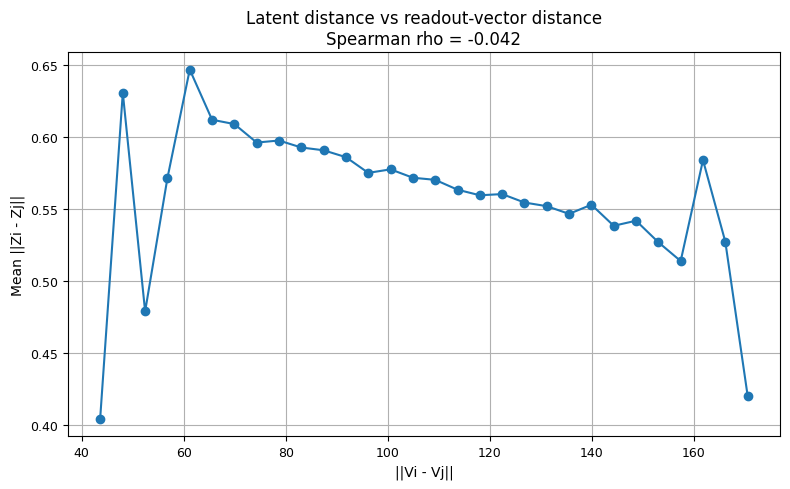

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

feature = "readout_weight"

# neurones valides
df = df_Z_full.dropna(subset=[feature]).copy()

idx = df["neuron_idx"].values

Z_valid = Z[idx]

# IMPORTANT : convertir la colonne de vecteurs en matrice
F = np.stack(
    df[feature].values
).astype(np.float32)

print("Z_valid shape:", Z_valid.shape)
print("F shape:", F.shape)

# -------------------------
# échantillonnage
# -------------------------

n_pairs = 200000
rng = np.random.default_rng(42)

i = rng.integers(0, len(df), n_pairs)
j = rng.integers(0, len(df), n_pairs)

mask = i != j
i = i[mask]
j = j[mask]

# -------------------------
# distances
# -------------------------

latent_dist = np.linalg.norm(
    Z_valid[i] - Z_valid[j],
    axis=1
)

feature_dist = np.linalg.norm(
    F[i] - F[j],
    axis=1
)

rho, pval = spearmanr(
    feature_dist,
    latent_dist
)

print(f"Spearman rho = {rho:.3f}, p = {pval:.2e}")

# -------------------------
# dataframe
# -------------------------

res = pd.DataFrame({
    "feature_dist": feature_dist,
    "latent_dist": latent_dist
})

res["bin"] = pd.cut(
    res["feature_dist"],
    bins=30
)

curve = res.groupby("bin").agg(
    mean_latent=("latent_dist", "mean"),
    n_pairs=("latent_dist", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# -------------------------
# plot
# -------------------------

plt.figure(figsize=(8,5))

plt.plot(
    centers,
    curve["mean_latent"],
    marker="o"
)

plt.xlabel("||Vi - Vj||")
plt.ylabel("Mean ||Zi - Zj||")
plt.title(
    f"Latent distance vs readout-vector distance\nSpearman rho = {rho:.3f}"
)

plt.grid(True)
plt.tight_layout()
plt.show()